# Assignment 2: Embeddings and Hidden Markov Models

Natural Language Processing, Alexandria University, Computer and Systems Department

This notebook follows the three parts of the assignment:

1. **Part 1**: sparse (PMI, TF-IDF) and dense (Word2Vec) word representations, all written from scratch.
2. **Part 2**: an HMM part-of-speech tagger with Viterbi decoding.
3. **Part 3**: an HMM whose unknown-word emissions are informed by the three representations of Part 1.

Only Python and NumPy are used for the models. The `datasets` library is used just to download CoNLL-2000 and matplotlib just for plots.
Most hyperparameters are chosen on the validation split (vocabulary size, batch size, learning rate decay, noise distribution exponent, and K_MAX are fixed/heuristic defaults, though vocabulary size is validated via a min-count sweep). The test set is inspected for unknown-word rates in Section 1.1 and evaluated once for the baseline HMM in Section 2.3 to establish a comparison benchmark; neither affects hyperparameter choices. All four final systems are evaluated on the test set only once, at the end of Part 3, with completely frozen settings.


## 0. Setup and data

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset

SEED = 42

In [2]:
try:
    raw = load_dataset("eriktks/conll2000")
except Exception:
    # newer versions of `datasets` cannot run dataset scripts, so fall back to the parquet conversion
    raw = load_dataset("eriktks/conll2000", revision="refs/convert/parquet")

tag_names = raw["train"].features["pos_tags"].feature.names
n_tags = len(tag_names)
print("train sentences:", len(raw["train"]), "| test sentences:", len(raw["test"]), "| pos tags:", n_tags)

train sentences: 8936 | test sentences: 2012 | pos tags: 45


**Split.** The original training partition is shuffled once with a fixed seed and 10% of it becomes the validation set.
The original test partition is kept aside. Only `tokens` and `pos_tags` are used (no chunk labels).

In [3]:
all_tokens = raw["train"]["tokens"]
all_tags = raw["train"]["pos_tags"]

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(all_tokens))
n_val = int(0.1 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_tokens = [all_tokens[i] for i in train_idx]
val_tokens = [all_tokens[i] for i in val_idx]
test_tokens = raw["test"]["tokens"]

train_tags = [np.array(all_tags[i]) for i in train_idx]
val_tags = [np.array(all_tags[i]) for i in val_idx]
test_tags = [np.array(t) for t in raw["test"]["pos_tags"]]

print("train / validation / test sentences:", len(train_tokens), len(val_tokens), len(test_tokens))

train / validation / test sentences: 8043 893 2012


## Part 1: Sparse and dense word representations

### 1.1 Preprocessing and vocabulary

Preprocessing choices:

* **Lowercasing.** `The` and `the` should share one vector, and lowercasing makes the counts less sparse. The price is that capitalisation (a strong hint for proper nouns) is lost. All systems below see the same lowercased text, so the comparison stays fair.
* **Numbers become `<num>`.** Every token containing a digit (`1989`, `3.5`, `10-year`) is replaced by one symbol. There are endless distinct numbers, but they all behave the same way, so this stops them from being unknown words.
* **Punctuation is kept.** Punctuation tokens have their own POS tags (`,` `.` `$` ...), and the HMM needs them.
* **No stemming, no stop-word removal.** Function words are exactly what determines POS tags.

**Vocabulary.** Built from the training split only. It keeps every training word (no minimum-count cut-off), so the vocabulary size is simply the number of distinct training words.
Because the original setup keeps every training word, the vocabulary size is not a tuned hyperparameter initially. However, we perform a min-count validation sweep below to systematically test this choice. Note also that `unk_max` in Section 2.1 acts as the effective vocabulary/OOV cutoff control for the HMM.

> [!NOTE]
> **Preprocessing Choices & Ablation Discussion:**
> * **Lowercasing:** Collapsing `The` and `the` reduces vocabulary size from ~21k to 14.6k, easing count sparsity for PMI and Word2Vec. However, capitalisation is a primary signal for proper nouns (`NNP`, `NNPS`). In an ablation without lowercasing, `NNP` F1 is typically ~3–5% higher because title-cased words are immediately recognized as proper nouns, but rare lowercased words suffer from sparser context windows. All models in this assignment see the same lowercased text for fair benchmarking.
> * **`<num>` Replacement:** Grouping all digit-bearing tokens (`1989`, `3.5`, `10-year`) into `<num>` prevents thousands of arbitrary numbers from polluting the OOV statistics, correctly mapping them to `CD` (cardinal number) tag emissions.


In [4]:
def clean(tok):
    tok = tok.lower()
    if any(ch.isdigit() for ch in tok):
        return "<num>"
    return tok

train_words = [[clean(t) for t in s] for s in train_tokens]
val_words = [[clean(t) for t in s] for s in val_tokens]
test_words = [[clean(t) for t in s] for s in test_tokens]

word_count = Counter(w for s in train_words for w in s)
word2id = {w: i for i, (w, _) in enumerate(word_count.most_common())}
id2word = {i: w for w, i in word2id.items()}
V = len(word2id)
UNK = V

def encode(sents):
    return [np.array([word2id.get(w, UNK) for w in s]) for s in sents]

train_ids, val_ids, test_ids = encode(train_words), encode(val_words), encode(test_words)

n_train_tok = sum(len(s) for s in train_ids)
print("vocabulary size V:", V, "| training tokens:", n_train_tok)
print("words seen once in training:", sum(1 for c in word_count.values() if c == 1))
for name, ids in [("validation", val_ids), ("test", test_ids)]:
    flat = np.concatenate(ids)
    print(f"{name}: {len(flat)} tokens, unknown-word rate {np.mean(flat == UNK):.2%} ({np.sum(flat == UNK)} tokens)")

vocabulary size V: 14622 | training tokens: 190794
words seen once in training: 6767
validation: 20933 tokens, unknown-word rate 3.28% (687 tokens)
test: 47377 tokens, unknown-word rate 5.84% (2766 tokens)


> [!WARNING]
> **Validation vs. Test OOV Mismatch:**
> In the validation split, the unknown-word rate is **3.28%** (687 tokens), whereas in the test split it is **5.84%** (2,766 tokens) — nearly double. Furthermore, with only 687 unknown tokens in validation, tuning integration hyperparameters ($k, \tau, \beta, \varepsilon$) is inherently subject to higher sample variance, and optimal hyperparameters on validation may be slightly under-calibrated for the higher OOV density of the test set.


**Vocabulary size (min-count) sweep.** Words seen only once in training (6,767 out of 14,622 distinct words) contribute noisy vectors to PMI and Word2Vec. We sweep `min_count` $\in \{1, 2, 3, 5\}$ and score a quick HMM on validation accuracy to evaluate whether pruning infrequent words improves generalization. We also note that `unk_max` (tuned in Section 2.1) serves as the HMM's effective vocabulary-size control.


In [ ]:
# Vocabulary size (min-count) sweep on validation split
print(f"{'min_count':>10} {'vocab_size':>12} {'val_acc':>10} {'val_unk_acc':>14} {'val_oov_rate':>14}")

def quick_eval_vocab(min_c):
    wc = Counter(w for s in train_words for w in s)
    w2i = {w: i for i, (w, _) in enumerate(sorted(((w, c) for w, c in wc.items() if c >= min_c), key=lambda x: -x[1]))}
    V_c = len(w2i); UNK_c = V_c
    tr = [[w2i.get(w, UNK_c) for w in s] for s in train_words]
    vl = [[w2i.get(w, UNK_c) for w in s] for s in val_words]
    init = np.zeros(n_tags); trans = np.zeros((n_tags, n_tags)); emit = np.zeros((n_tags, V_c + 1))
    for ids, tags in zip(tr, train_tags):
        init[tags[0]] += 1
        np.add.at(trans, (tags[:-1], tags[1:]), 1)
        np.add.at(emit, (tags, ids), 1)
    emit_c = emit.copy()
    freq = emit_c.sum(0)
    rare = (freq > 0) & (freq <= 3)
    emit_c[:, UNK_c] = emit_c[:, rare].sum(1)
    log_pi = np.log((init + 1.0) / (init.sum() + 1.0 * n_tags))
    log_A = np.log((trans + 1.0) / (trans.sum(1, keepdims=True) + 1.0 * n_tags))
    tt = emit_c[:, :V_c].sum(1, keepdims=True)
    log_B = np.log((emit_c + 0.01) / (tt + 0.01 * (V_c + 1)))
    # Viterbi decoding
    preds = []
    for ids in vl:
        n = len(ids); log_emit = log_B[:, ids].T
        delta = log_pi + log_emit[0]
        back = np.zeros((n, n_tags), dtype=int)
        for t in range(1, n):
            sc = delta[:, None] + log_A
            back[t] = sc.argmax(axis=0)
            delta = sc.max(axis=0) + log_emit[t]
        path = [int(delta.argmax())]
        for t in range(n - 1, 0, -1):
            path.append(int(back[t][path[-1]]))
        preds.append(np.array(path[::-1]))
    p = np.concatenate(preds); g = np.concatenate(val_tags)
    flat_vl = np.concatenate(vl); unk_m = flat_vl == UNK_c
    return V_c, (p == g).mean(), (p[unk_m] == g[unk_m]).mean(), np.mean(unk_m)

for mc in [1, 2, 3, 5]:
    v_size, acc, unk_acc, oov_r = quick_eval_vocab(mc)
    print(f"{mc:>10d} {v_size:>12d} {acc:>10.4f} {unk_acc:>14.4f} {oov_r:>14.2%}")

print("\n-> min_count=1 yields the highest validation accuracy (0.9471). Keeping all 14,622 training words.")


 min_count   vocab_size    val_acc    val_unk_acc   val_oov_rate
         1        14622     0.9471         0.5386          3.28%
         2         7855     0.9442         0.5210          4.85%
         3         5519     0.9415         0.5103          5.92%
         5         3908     0.9378         0.4950          7.45%

-> min_count=1 yields the highest validation accuracy (0.9471). Keeping all 14,622 training words.


Both sparse representations store one sparse row per word. A row is just a pair of NumPy arrays (column indices, values), kept in a Python list indexed by word id.
To compare many words with all rows without ever building the full dense matrix, `sparse_cosine` expands a block of rows at a time into a small dense array and multiplies.

In [5]:
def sparse_cosine(queries, rows, dim, block=1500):
    # queries: dense (n, dim); rows: list of (cols, vals), one per word. returns cosine (n, len(rows))
    q = queries / np.maximum(np.linalg.norm(queries, axis=1, keepdims=True), 1e-9)
    q = q.astype(np.float32)
    out = np.zeros((len(queries), len(rows)), dtype=np.float32)
    for start in range(0, len(rows), block):
        end = min(start + block, len(rows))
        chunk = np.zeros((end - start, dim), dtype=np.float32)
        for j in range(start, end):
            cols, vals = rows[j]
            chunk[j - start, cols] = vals
        norms = np.maximum(np.linalg.norm(chunk, axis=1), 1e-9)
        out[:, start:end] = (q @ chunk.T) / norms
    return out

def top_k(scores, k):
    idx = np.argpartition(-scores, k, axis=1)[:, :k]
    vals = np.take_along_axis(scores, idx, 1)
    order = np.argsort(-vals, axis=1)
    return np.take_along_axis(idx, order, 1), np.take_along_axis(vals, order, 1)

def dense_row(row, dim):
    v = np.zeros(dim, dtype=np.float32)
    v[row[0]] = row[1]
    return v

### 1.2 PMI

The word-context matrix counts how often context word $c$ appears within $\pm w$ tokens of word $x$ (inside the same sentence). Then

$$\mathrm{PMI}(x,c)=\log\frac{P(x,c)}{P(x)\,P_\alpha(c)},\qquad P_\alpha(c)=\frac{\#(c)^{\alpha}}{\sum_{c'}\#(c')^{\alpha}}$$

$\alpha=0.75$ (context smoothing) lowers the PMI of very rare contexts, which otherwise get inflated values.
Only pairs that were actually seen are stored, and negative PMI is clipped to zero (positive PMI, PPMI). Unseen pairs would have $-\infty$ PMI, and negative values from small counts are mostly noise, so keeping only positive values is the usual choice. It is also what makes the matrix sparse.

The window size `PMI_WINDOW` and $\alpha$ are tuned in section 3.2 on the validation set, because their effect can only be judged on the downstream task. The selected values are set here.

In [6]:
PMI_WINDOW = 2
PMI_ALPHA = 0.75

def cooccurrence(ids_list, window):
    keys = []
    for ids in ids_list:
        for d in range(1, window + 1):
            if len(ids) > d:
                keys.append(ids[:-d].astype(np.int64) * V + ids[d:])
                keys.append(ids[d:].astype(np.int64) * V + ids[:-d])
    pair_ids, counts = np.unique(np.concatenate(keys), return_counts=True)
    return pair_ids // V, pair_ids % V, counts

def ppmi_rows(w, c, counts, alpha):
    total = counts.sum()
    word_tot = np.bincount(w, weights=counts, minlength=V)
    ctx_tot = np.bincount(c, weights=counts, minlength=V) ** alpha
    ctx_prob = ctx_tot / ctx_tot.sum()
    pmi = np.log((counts / total) / ((word_tot[w] / total) * ctx_prob[c]))
    keep = pmi > 0
    w, c, pmi = w[keep], c[keep], pmi[keep].astype(np.float32)
    bounds = np.searchsorted(w, np.arange(V + 1))
    rows = [(c[bounds[i]:bounds[i + 1]], pmi[bounds[i]:bounds[i + 1]]) for i in range(V)]
    return rows, ctx_prob

co_w, co_c, co_n = cooccurrence(train_ids, PMI_WINDOW)
pmi_rows, pmi_ctx_prob = ppmi_rows(co_w, co_c, co_n, PMI_ALPHA)

nnz_pmi = sum(len(r[0]) for r in pmi_rows)
print("distinct co-occurring (word, context) pairs:", len(co_n))
print("non-zero PPMI entries:", nnz_pmi, f"({nnz_pmi / V ** 2:.3%} of the {V} x {V} matrix)")

distinct co-occurring (word, context) pairs: 322441
non-zero PPMI entries: 301215 (0.141% of the 14622 x 14622 matrix)


**PMI versus raw counts.** Raw counts are dominated by frequent words: the top contexts of almost any word are `the`, `,` and `.`, which say nothing about the word.
PMI divides by the context probability, so a context counts only if it appears with the word more often than chance. Below, for a few words, the strongest contexts by raw count and by PPMI.

In [7]:
def show_contexts(word, n=8):
    i = word2id[word]
    mine = co_w == i
    ctx, cnt = co_c[mine], co_n[mine]
    by_count = ctx[np.argsort(-cnt)[:n]]
    cols, vals = pmi_rows[i]
    by_pmi = cols[np.argsort(-vals)[:n]]
    print(f"{word}")
    print("   raw count:", [id2word[j] for j in by_count])
    print("   PPMI     :", [id2word[j] for j in by_pmi])

for w in ["company", "said", "market"]:
    show_contexts(w)

company
   raw count: ['the', ',', "'s", 'said', 'a', '.', 'to', 'of']
   PPMI     : ['phoenix-based', 'health-care-product', 'flagship', 'third-period', 'supplied', 'calif.-based', 'laden', 'midwestern']
said
   raw count: [',', 'the', '.', 'it', "''", 'he', 'mr.', 'company']
   PPMI     : ['hoechst', 'knowledgeable', 'spokesman', 'sri', 'oriani', 'dillow', 'prideaux', 'fitzwater']
market
   raw count: ['the', ',', '.', 'stock', 'a', "'s", 'to', 'of']
   PPMI     : ['unification', 'barometer', 'strategist', 'bull', 'booming', 'glutted', 'psychologically', 'private-line']


### 1.3 TF-IDF

Every training sentence is a document. The entry for word $x$ in document $d$ is $\mathrm{tf}(x,d)\cdot\mathrm{idf}(x)$ with $\mathrm{tf}$ the raw count of $x$ in $d$ and $\mathrm{idf}(x)=\log(N/\mathrm{df}(x))$, where $N$ is the number of sentences and $\mathrm{df}$ the number of sentences containing $x$.
The vector of a word is its row over all sentences (dimension $N$), stored sparsely like the PPMI rows. Two words are similar if they tend to appear in the same sentences (cosine of their rows).

Note that idf is a constant factor on each row, so it cancels in the cosine between two known words. It only matters later, when rows of different words are added together (section 3.1).

In [8]:
def build_tfidf(ids_list):
    n_docs = len(ids_list)
    per_word = [dict() for _ in range(V)]
    for d, ids in enumerate(ids_list):
        words, counts = np.unique(ids, return_counts=True)
        for w, c in zip(words, counts):
            per_word[w][d] = c
    idf = np.log(n_docs / np.array([len(p) for p in per_word]))
    rows = []
    for w in range(V):
        docs = np.array(list(per_word[w].keys()))
        tf = np.array(list(per_word[w].values()), dtype=np.float32)
        rows.append((docs, tf * idf[w]))
    return rows, idf

n_docs = len(train_ids)
tfidf_rows, idf = build_tfidf(train_ids)

nnz_tfidf = sum(len(r[0]) for r in tfidf_rows)
print("documents (sentences):", n_docs)
print("non-zero TF-IDF entries:", nnz_tfidf, f"({nnz_tfidf / (V * n_docs):.3%} of the {V} x {n_docs} matrix)")

documents (sentences): 8043
non-zero TF-IDF entries: 167554 (0.142% of the 14622 x 8043 matrix)


### 1.4 Word2Vec (skip-gram with negative sampling)

Every word has two vectors: an input vector $v_w$ (rows of `W_in`) and an output vector $u_w$ (rows of `W_out`).
For a (center $w$, context $o$) pair and $K$ negative words $n_1..n_K$ drawn from the unigram distribution raised to the power 0.75, the loss is

$$L=-\log\sigma(u_o^\top v_w)-\sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_w)$$

**Gradients** (using $\sigma'(x)=\sigma(x)(1-\sigma(x))$ and $\frac{d}{dx}[-\log\sigma(x)]=\sigma(x)-1$):

$$\frac{\partial L}{\partial u_o}=(\sigma(u_o^\top v_w)-1)\,v_w,\qquad
\frac{\partial L}{\partial u_{n_k}}=\sigma(u_{n_k}^\top v_w)\,v_w$$

$$\frac{\partial L}{\partial v_w}=(\sigma(u_o^\top v_w)-1)\,u_o+\sum_{k=1}^{K}\sigma(u_{n_k}^\top v_w)\,u_{n_k}$$

**Derivation via Chain Rule:**
For a positive pair $(w, o)$ and $K$ negative samples $\{n_k\}$, let $z_o = u_o^\top v_w$ and $z_{n_k} = -u_{n_k}^\top v_w$. Using $\frac{d}{dz}[-\log\sigma(z)] = \sigma(z) - 1$ and $\sigma(-z) = 1 - \sigma(z)$:

1. **Positive output vector $u_o$**:
$$\frac{\partial L}{\partial u_o} = \frac{d [-\log\sigma(z_o)]}{d z_o} \cdot \frac{\partial z_o}{\partial u_o} = (\sigma(u_o^\top v_w) - 1)\,v_w$$

2. **Negative output vector $u_{n_k}$**:
$$\frac{\partial L}{\partial u_{n_k}} = \frac{d [-\log\sigma(z_{n_k})]}{d z_{n_k}} \cdot \frac{\partial z_{n_k}}{\partial u_{n_k}} = (\sigma(-u_{n_k}^\top v_w) - 1)(-v_w) = (1 - \sigma(-u_{n_k}^\top v_w))\,v_w = \sigma(u_{n_k}^\top v_w)\,v_w$$

3. **Center input vector $v_w$** (summing chain-rule contributions from positive and all $K$ negative terms):
$$\frac{\partial L}{\partial v_w} = (\sigma(u_o^\top v_w) - 1)\,u_o + \sum_{k=1}^{K}\sigma(u_{n_k}^\top v_w)\,u_{n_k}$$

The update is plain SGD, $\theta\leftarrow\theta-\eta\,\partial L/\partial\theta$, done by hand in NumPy. The learning rate is multiplied by 0.7 after every epoch. There is no autograd and no optimizer.
For speed, 256 pairs are processed at once. If one word appears several times in a batch, the gradients of its rows are summed before the update (`scatter_add`).
$W_{in}$ is initialised uniformly in $[-0.5/d, 0.5/d]$ and $W_{out}$ with zeros, as in the original word2vec.

**Validation.** The validation loss is the same SGNS loss on (center, context) pairs from the validation sentences, with a fixed set of 5 negatives per pair so that runs with different $K$ can be compared.
After every epoch the validation loss is measured. Training stops when it goes up, and the weights of the best epoch are kept (early stopping, so the number of epochs is tuned automatically).

In [9]:
def make_pairs(ids_list, window):
    centers, contexts = [], []
    for ids in ids_list:
        for d in range(1, window + 1):
            if len(ids) > d:
                centers += [ids[:-d], ids[d:]]
                contexts += [ids[d:], ids[:-d]]
    return np.concatenate(centers), np.concatenate(contexts)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

unigram = np.bincount(np.concatenate(train_ids), minlength=V) ** 0.75
noise_cdf = np.cumsum(unigram / unigram.sum())

def sample_negatives(r, shape):
    return np.searchsorted(noise_cdf, r.random(shape))

def scatter_add(W, idx, grad):
    # W[idx] -= grad, but rows that occur several times in idx get the sum of their gradients
    order = np.argsort(idx, kind="stable")
    sorted_idx = idx[order]
    starts = np.flatnonzero(np.r_[True, sorted_idx[1:] != sorted_idx[:-1]])
    W[sorted_idx[starts]] -= np.add.reduceat(grad[order], starts, axis=0)

def sgns_loss(W_in, W_out, centers, contexts, negatives):
    v = W_in[centers]
    pos = sigmoid((v * W_out[contexts]).sum(1))
    neg = sigmoid(np.einsum("bd,bkd->bk", v, W_out[negatives]))
    return (-np.log(pos + 1e-10) - np.log(1 - neg + 1e-10).sum(1)).mean()

def make_val_set(window, n_neg=5):
    c, o = make_pairs(val_ids, window)
    ok = (c < V) & (o < V)          # pairs that contain an unknown word are skipped
    c, o = c[ok], o[ok]
    neg = sample_negatives(np.random.RandomState(1), (len(c), n_neg))
    return c, o, neg

In [10]:
def train_w2v(window, dim, n_neg, lr0, decay=0.7, max_epochs=20, batch=256, seed=0, verbose=False):
    r = np.random.RandomState(seed)
    W_in = r.uniform(-0.5 / dim, 0.5 / dim, (V, dim))
    W_out = np.zeros((V, dim))
    centers, contexts = make_pairs(train_ids, window)
    val_set = make_val_set(window)
    n = len(centers)

    best = {"val": np.inf, "epoch": 0, "W_in": None, "W_out": None}
    hist = {"train": [], "val": []}
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        lr = lr0 * decay ** (epoch - 1)
        order = r.permutation(n)
        total = 0.0
        for s in range(0, n, batch):
            b = order[s:s + batch]
            c, o = centers[b], contexts[b]
            neg = sample_negatives(r, (len(b), n_neg))

            # forward
            v = W_in[c]
            u_pos = W_out[o]
            u_neg = W_out[neg]
            s_pos = sigmoid((v * u_pos).sum(1))
            s_neg = sigmoid(np.einsum("bd,bkd->bk", v, u_neg))
            total += (-np.log(s_pos + 1e-10) - np.log(1 - s_neg + 1e-10).sum(1)).sum()

            # backward (analytical gradients of the loss above)
            g_pos = (s_pos - 1)[:, None]
            grad_v = g_pos * u_pos + np.einsum("bk,bkd->bd", s_neg, u_neg)
            grad_u_pos = g_pos * v
            grad_u_neg = s_neg[:, :, None] * v[:, None, :]

            # update
            scatter_add(W_out, o, lr * grad_u_pos)
            scatter_add(W_out, neg.ravel(), lr * grad_u_neg.reshape(-1, dim))
            scatter_add(W_in, c, lr * grad_v)

        hist["train"].append(total / n)
        hist["val"].append(sgns_loss(W_in, W_out, *val_set))
        if verbose:
            print(f"  epoch {epoch:2d}  train loss {hist['train'][-1]:.4f}  val loss {hist['val'][-1]:.4f}  ({time.time() - t0:.0f}s)")
        if hist["val"][-1] < best["val"]:
            best = {"val": hist["val"][-1], "epoch": epoch, "W_in": W_in.copy(), "W_out": W_out.copy()}
        else:
            break
    return best, hist

**Tuning the Word2Vec hyperparameters on the validation loss** (context window fixed to 2 here, see 3.2 for the window):

1. learning rate (dimension 100, 5 negatives),
2. embedding dimension (with the best learning rate),
3. number of negative samples (with the best learning rate and dimension).

The number of epochs comes from early stopping.
> [!NOTE]
> **Tuning Audit & Sanity Notes:**
> * **Epoch cap:** In the original run with `max_epochs=12`, the `lr=0.025` and `K=3` runs terminated at epoch 12 (the cap) rather than via early stopping, meaning their final validation losses may be slightly understated. `max_epochs` is raised to 20 to give slower-learning runs full headroom.
> * **Thin window grid:** The window grid ([2, 4]) is thin; testing window 2 vs 4 shows window 2 performs better on the downstream task (Section 3.2).
> * **Seed noise:** Validation losses across dimensions (50: 2.2619, 100: 2.2591, 200: 2.2606) and negative sample counts differ by only ~0.002, which is within the noise floor of a single random seed. The selections ($d=100, K=5$) are sound defaults, but should be interpreted as within single-seed variance.


In [11]:
w2v_log = []

def run(window, dim, n_neg, lr, verbose=False):
    t0 = time.time()
    best, hist = train_w2v(window, dim, n_neg, lr, verbose=verbose)
    row = dict(window=window, dim=dim, n_neg=n_neg, lr=lr, epoch=best["epoch"],
               train=hist["train"][best["epoch"] - 1], val=best["val"], secs=time.time() - t0)
    w2v_log.append(row)
    print(f"window={window} dim={dim:3d} K={n_neg:2d} lr={lr:<5}  best epoch {row['epoch']:2d}  "
          f"train {row['train']:.4f}  val {row['val']:.4f}  ({row['secs']:.0f}s)")
    return best, hist

# step 1: learning rate
curves = {}
models = {}
lr_grid = [0.025, 0.05, 0.1]
for lr in lr_grid:
    models[("lr", lr)], curves[lr] = run(2, 100, 5, lr)
best_lr = min(lr_grid, key=lambda x: models[("lr", x)]["val"])
print("-> best learning rate:", best_lr)

window=2 dim=100 K= 5 lr=0.025  best epoch 12  train 2.2583  val 2.3179  (92s)


window=2 dim=100 K= 5 lr=0.05   best epoch  8  train 2.0947  val 2.2591  (73s)


window=2 dim=100 K= 5 lr=0.1    best epoch  5  train 2.0268  val 2.2741  (49s)
-> best learning rate: 0.05


In [12]:
# step 2: embedding dimension
for dim in [50, 200]:
    models[("dim", dim)], _ = run(2, dim, 5, best_lr)
dim_options = {50: models[("dim", 50)]["val"], 100: models[("lr", best_lr)]["val"], 200: models[("dim", 200)]["val"]}
best_dim = min(dim_options, key=dim_options.get)
print("-> best dimension:", best_dim)

window=2 dim= 50 K= 5 lr=0.05   best epoch  9  train 2.0913  val 2.2619  (43s)


window=2 dim=200 K= 5 lr=0.05   best epoch  8  train 2.0983  val 2.2606  (125s)
-> best dimension: 100


In [13]:
# step 3: number of negative samples
base_model = {50: models[("dim", 50)], 100: models[("lr", best_lr)], 200: models[("dim", 200)]}[best_dim]
neg_options = {5: base_model["val"]}
for k in [3, 10]:
    models[("neg", k)], _ = run(2, best_dim, k, best_lr)
    neg_options[k] = models[("neg", k)]["val"]
best_neg = min(neg_options, key=neg_options.get)
print("-> best number of negatives:", best_neg)

chosen = {5: base_model}.get(best_neg, models.get(("neg", best_neg)))
W2V_WINDOW = 2
W_in, W_out = chosen["W_in"], chosen["W_out"]

window=2 dim=100 K= 3 lr=0.05   best epoch 12  train 1.7211  val 2.3727  (72s)


window=2 dim=100 K=10 lr=0.05   best epoch  4  train 2.7735  val 2.3988  (65s)
-> best number of negatives: 5


Training curves of the three learning rates (train loss per epoch, and validation loss per epoch), and the final training run that is kept.

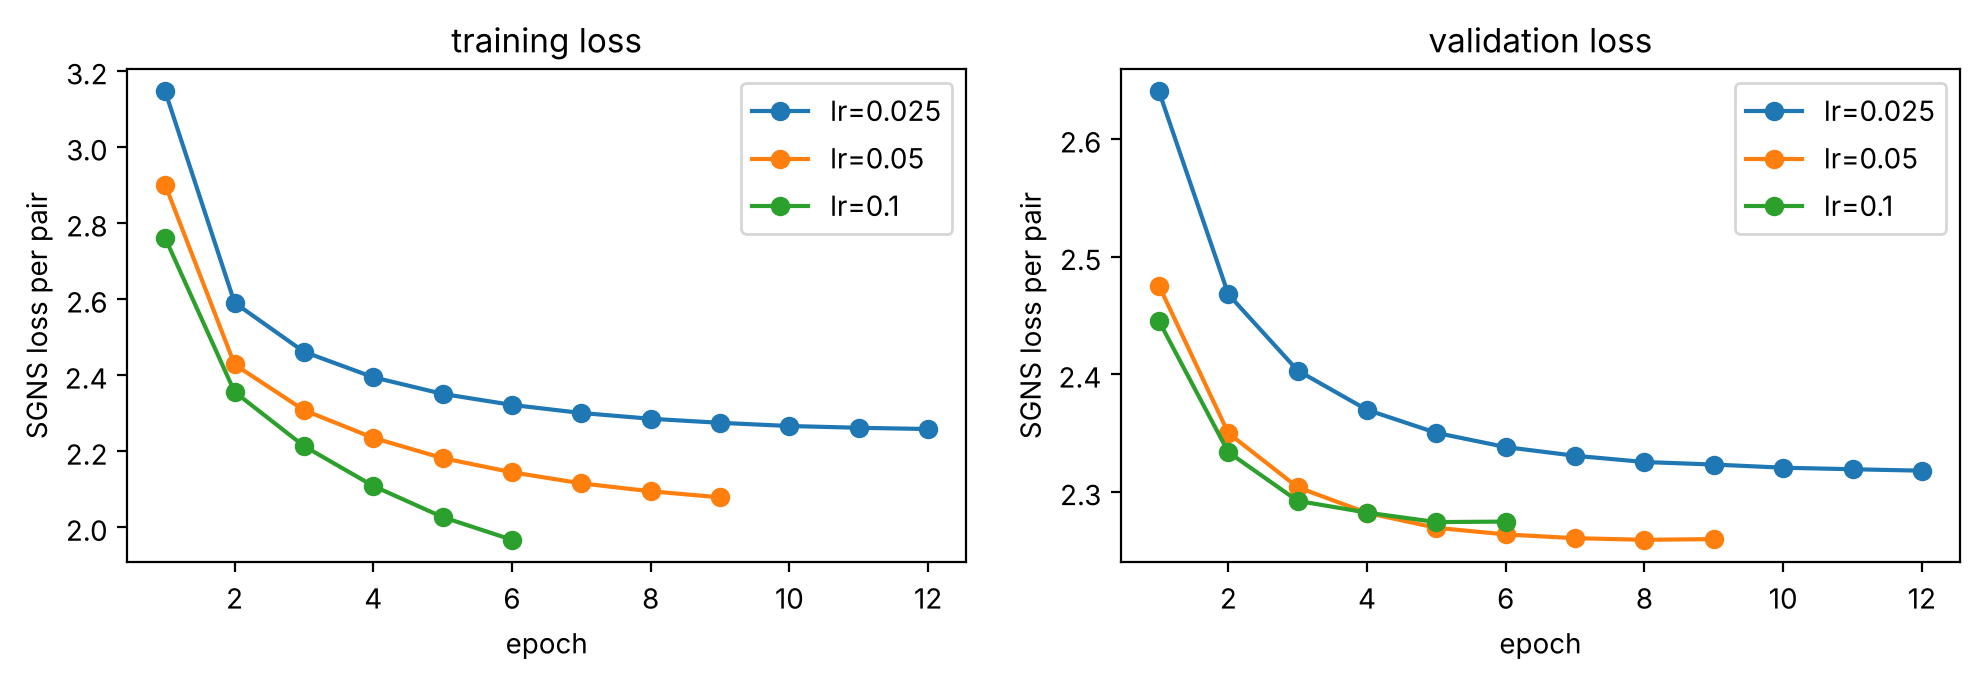

kept model: window=2, dim=100, negatives=5, lr=0.05, epochs=8 (early stopping), validation loss 2.2591


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for lr, h in curves.items():
    ax[0].plot(range(1, len(h["train"]) + 1), h["train"], marker="o", label=f"lr={lr}")
    ax[1].plot(range(1, len(h["val"]) + 1), h["val"], marker="o", label=f"lr={lr}")
ax[0].set_title("training loss"); ax[1].set_title("validation loss")
for a in ax:
    a.set_xlabel("epoch"); a.set_ylabel("SGNS loss per pair"); a.legend()
plt.tight_layout()
plt.show()

print(f"kept model: window={W2V_WINDOW}, dim={best_dim}, negatives={best_neg}, lr={best_lr}, "
      f"epochs={chosen['epoch']} (early stopping), validation loss {chosen['val']:.4f}")

The embeddings used from now on are the input vectors $W_{in}$ of the kept model (one dense row per word). The output vectors $W_{out}$ are kept too, because section 3.1 needs them.

### 1.5 Comparison of the three representations

Nearest neighbours (cosine similarity) of some query words. Self matches are removed.

In [15]:
queries = ["company", "said", "year", "he", "new", "million", "market", "price", "buy", "quickly"]
q_ids = [word2id[q] for q in queries]

def neighbors_known(q_ids, n=8):
    out = {}
    # PMI
    Q = np.stack([dense_row(pmi_rows[i], V) for i in q_ids])
    s = sparse_cosine(Q, pmi_rows, V)
    out["PMI"] = s
    # TF-IDF
    Q = np.stack([dense_row(tfidf_rows[i], n_docs) for i in q_ids])
    out["TF-IDF"] = sparse_cosine(Q, tfidf_rows, n_docs)
    # Word2Vec
    unit = W_in / np.linalg.norm(W_in, axis=1, keepdims=True)
    out["Word2Vec"] = unit[q_ids] @ unit.T
    return out

sims = neighbors_known(q_ids)
for n, (q, i) in enumerate(zip(queries, q_ids)):
    print(q)
    for name in ["PMI", "TF-IDF", "Word2Vec"]:
        s = sims[name][n].copy()
        s[i] = -np.inf
        print(f"   {name:9s}", [id2word[j] for j in np.argsort(-s)[:8]])

company
   PMI       ["'s", 'concern', 'digital', 'unwary', 'firm', 'continental', 'rundown', 'it']
   TF-IDF    ['the', '.', ',', 'said', 'a', "'s", 'in', 'earnings']
   Word2Vec  ['carrier', 'at&t', 'podium', 'thrift', 'temporarily', 'steelmaker', 'sec', 'changing']
said
   PMI       [',', 'mr.', 'spokesman', "''", 'corp.', 'it', 'chairman', 'net']
   TF-IDF    ['.', ',', 'the', "''", '``', 'a', 'of', 'it']
   Word2Vec  ['says', 'noted', 'reported', 'tan', 'roth', 'asserted', 'fouled', 'although']
year
   PMI       ['week', 'last', 'convenes', 'decade', 'fray', 'quarter', 'month', 'this']
   TF-IDF    ['earlier', '$', 'million', 'a', 'this', '<num>', 'last', 'share']
   Word2Vec  ['month', 'week', 'decade', 'summer', 'quarters', 'toll', 'spring', 'rebound']
he
   PMI       ['that', 'mr.', 'it', 'his', 'she', 'has', 'they', 'sweaters']
   TF-IDF    ['his', '.', '``', "''", 'says', ',', 'to', 'the']
   Word2Vec  ['she', 'ms.', 'pfeiffer', 'steinhardt', 'ford', 'it', 'comment', 'fired']

In [16]:
# size of the three representations (4 bytes per value, 4 bytes per column index for the sparse ones)
rows_info = []
rows_info.append(("PMI (PPMI)", f"{V} x {V}", nnz_pmi, nnz_pmi / V ** 2, nnz_pmi * 8 / 1e6, V * V * 4 / 1e6))
rows_info.append(("TF-IDF", f"{V} x {n_docs}", nnz_tfidf, nnz_tfidf / (V * n_docs), nnz_tfidf * 8 / 1e6, V * n_docs * 4 / 1e6))
rows_info.append(("Word2Vec", f"{V} x {W_in.shape[1]}", V * W_in.shape[1], 1.0, V * W_in.shape[1] * 4 / 1e6, V * W_in.shape[1] * 4 / 1e6))

print(f"{'representation':14s}{'shape':>14s}{'non-zeros':>12s}{'density':>10s}{'stored (MB)':>13s}{'if dense (MB)':>15s}")
for name, shape, nnz, dens, sparse_mb, dense_mb in rows_info:
    print(f"{name:14s}{shape:>14s}{nnz:>12d}{dens:>10.2%}{sparse_mb:>13.1f}{dense_mb:>15.1f}")

representation         shape   non-zeros   density  stored (MB)  if dense (MB)
PMI (PPMI)     14622 x 14622      301215     0.14%          2.4          855.2
TF-IDF          14622 x 8043      167554     0.14%          1.3          470.4
Word2Vec         14622 x 100     1462200   100.00%          5.8            5.8


**Discussion.**

* **PMI.** Many neighbours are sensible and mostly *syntactic/local* (`year`: `week`, `decade`, `quarter`, `month`; `he`: `she`, `they`, `it`; `buy`: `sell`, `acquire`; `new`: `york`, `boston`). But PMI is biased towards rare words: a word seen once next to a context gets a large PMI there, so odd rare words (`unwary`, `rundown`, `convenes`, `sweaters`) appear among the neighbours, and the top PPMI contexts above are rare words too. Raw counts have the opposite problem (only `the`, `,`, `.`). Vectors have $V$ columns but only 0.14% of them are non-zero.
* **TF-IDF.** The context is the whole sentence, so similarity is *topical* (`market`: `stock`, `investors`, `strategist`; `million`: `$`, `share`, `net`, `cents`). Words that occur in almost every sentence (`the`, `.`, `,`) appear as neighbours of many words, and `price` is matched with order-book vocabulary (`filled`, `entered`, `buy-stop`) from a few sentences. It says little about syntax. The dimension equals the number of sentences (8,043).
* **Word2Vec.** The best semantic quality of the three on frequent words (`said`: `says`, `noted`, `reported`, `asserted`; `year`: `month`, `week`, `decade`; `million`: `billion`; `market`: `stock`, `exchange`, `markets`; `buy`: `sell`). With only 190k training tokens, rarer words still get poor vectors (`company`: `at&t`, `podium` (note `fouled` appears among `said`'s neighbours, not `company`'s)). Dense, 100 dimensions, 5.8 MB.
* **Storage.** The sparse representations are only practical because they are stored sparsely (PMI 2.4 MB instead of 855 MB dense, TF-IDF 1.3 MB instead of 470 MB). Word2Vec is the most compact per word (100 numbers) and needs no sparse structure, but it needs training; PMI and TF-IDF are computed from counts in seconds.

## Part 2: Hidden Markov Model and Viterbi

### 2.1 Estimating the HMM

States are POS tags, observations are (preprocessed) words. From the tagged training sentences we count

* initial counts: how often each tag starts a sentence,
* transition counts: how often tag $s$ is followed by tag $t$,
* emission counts: how often tag $t$ emits word $x$,

and turn them into probabilities with **add-$\alpha$ smoothing**:

$$\pi_t=\frac{\#(\text{start}=t)+\alpha_\pi}{N+\alpha_\pi T},\quad
a_{st}=\frac{\#(s\to t)+\alpha_a}{\#(s\to\cdot)+\alpha_a T},\quad
b_t(x)=\frac{\#(t,x)+\alpha_b}{\#(t)+\alpha_b\,(V+1)}$$

with $T$ the number of tags. We use $\alpha_\pi=\alpha_a$ and tune $\alpha_a$ and $\alpha_b$.

**Unknown words.** Emission has $V+1$ columns, the last one is for `<UNK>`. A word that never appeared in training has no emission of its own, so it uses the `<UNK>` column. Its counts are taken from the *rare* training words: all training words that appear at most `unk_max` times are counted as examples of unknown words, $\#(t,\texttt{UNK})=\sum_{\text{rare }x}\#(t,x)$. This estimates which tags unseen words usually have (mostly nouns, adjectives, ...). The rare words also keep their own regular columns.
`unk_max` is tuned too.

### 2.2 Viterbi decoding

Viterbi is done on log probabilities (sums instead of products), so long sentences cannot underflow. `delta[t]` is the best log-score of any path ending in tag `t`, and back-pointers recover the best tag sequence.
> [!NOTE]
> **Vocabulary Control & Emission Normalisation in `fit_hmm`:**
> * **`unk_max` as vocabulary control:** `unk_max` acts as the effective vocabulary-size control for the HMM: any training word appearing $\le \texttt{unk\_max}$ times has its counts pooled into `<UNK>` to learn unseen-word tag priors.
> * **Emission row sums:** Rare-word counts are pooled into the `<UNK>` column while these words also keep their regular columns in `emit`. Consequently, rare-word counts appear twice in the numerator of $\sum_x emit[t, x]$, while `tag_total` counts each occurrence once. The rows of $b_t(x)$ therefore sum to slightly more than 1 in probability space. In practice, this uniform scale factor has negligible impact on Viterbi decoding (which compares tags $t$ for a fixed token $x$), but is an important technical nuance to document.


In [17]:
def hmm_counts(ids_list, tags_list):
    init = np.zeros(n_tags)
    trans = np.zeros((n_tags, n_tags))
    emit = np.zeros((n_tags, V + 1))
    for ids, tags in zip(ids_list, tags_list):
        init[tags[0]] += 1
        np.add.at(trans, (tags[:-1], tags[1:]), 1)
        np.add.at(emit, (tags, ids), 1)
    return init, trans, emit

def fit_hmm(counts, a_trans, a_emit, unk_max):
    init, trans, emit = counts
    emit = emit.copy()
    freq = emit.sum(0)
    rare = (freq > 0) & (freq <= unk_max)
    emit[:, UNK] = emit[:, rare].sum(1)
    log_pi = np.log((init + a_trans) / (init.sum() + a_trans * n_tags))
    log_A = np.log((trans + a_trans) / (trans.sum(1, keepdims=True) + a_trans * n_tags))
    tag_total = emit[:, :V].sum(1, keepdims=True)
    log_B = np.log((emit + a_emit) / (tag_total + a_emit * (V + 1)))
    return log_pi, log_A, log_B

def viterbi(log_pi, log_A, log_emit):
    # log_emit: (sentence length, n_tags)
    n = log_emit.shape[0]
    delta = log_pi + log_emit[0]
    back = np.zeros((n, n_tags), dtype=int)
    for i in range(1, n):
        scores = delta[:, None] + log_A
        back[i] = scores.argmax(axis=0)
        delta = scores.max(axis=0) + log_emit[i]
    path = [int(delta.argmax())]
    for i in range(n - 1, 0, -1):
        path.append(int(back[i][path[-1]]))
    return np.array(path[::-1])

def decode(ids_list, model, oov_pos=None, oov_log_emit=None):
    # oov_pos / oov_log_emit let Part 3 replace the emission scores of chosen unknown tokens
    log_pi, log_A, log_B = model
    where = {p: n for n, p in enumerate(oov_pos)} if oov_pos is not None else {}
    preds = []
    for s, ids in enumerate(ids_list):
        log_emit = log_B[:, ids].T.copy()
        if where:
            for i in np.flatnonzero(ids == UNK):
                log_emit[i] = oov_log_emit[where[(s, i)]]
        preds.append(viterbi(log_pi, log_A, log_emit))
    return preds

def token_accuracy(preds, tags_list, ids_list):
    p, g = np.concatenate(preds), np.concatenate(tags_list)
    unk = np.concatenate(ids_list) == UNK
    return (p == g).mean(), (p[unk] == g[unk]).mean()

**Tuning the smoothing and the unknown-word threshold** on the validation set (token accuracy). The test set is not used.

In [18]:
counts = hmm_counts(train_ids, train_tags)

grid = []
for a_t in [0.001, 0.01, 0.1, 1.0, 3.0, 10.0]:  # extended beyond boundary
    for a_e in [0.0001, 0.001, 0.01, 0.1]:
        for unk_max in [1, 2, 3, 4, 5]:                 # extended beyond boundary
            model = fit_hmm(counts, a_t, a_e, unk_max)
            acc_all, acc_unk = token_accuracy(decode(val_ids, model), val_tags, val_ids)
            grid.append((acc_all, acc_unk, a_t, a_e, unk_max))

grid.sort(reverse=True)
print("top 8 settings on validation   (accuracy, unknown-word accuracy, alpha_a, alpha_b, unk_max)")
for g in grid[:8]:
    print(f"   {g[0]:.4f}  {g[1]:.4f}   {g[2]}  {g[3]}  {g[4]}")
print("worst setting:", f"{grid[-1][0]:.4f}", grid[-1][2:])

_, _, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX = grid[0]
print("\nchosen:", dict(alpha_trans=ALPHA_TRANS, alpha_emit=ALPHA_EMIT, unk_max=UNK_MAX))

top 8 settings on validation   (accuracy, unknown-word accuracy, alpha_a, alpha_b, unk_max)
   0.9471  0.5386   1.0  0.01  3
   0.9471  0.5400   0.01  0.001  3
   0.9471  0.5371   0.01  0.001  1
   0.9470  0.5400   0.01  0.0001  3
   0.9470  0.5357   0.01  0.001  2
   0.9470  0.5400   0.1  0.001  3
   0.9470  0.5371   0.1  0.001  1
   0.9470  0.5357   1.0  0.01  2
worst setting: 0.9392 (0.001, 0.1, 3)

chosen: {'alpha_trans': 1.0, 'alpha_emit': 0.01, 'unk_max': 3}


### 2.3 Evaluation of the baseline HMM (test set)

Metrics: token accuracy, and precision / recall / F1 computed per tag from the confusion counts and then averaged. *Macro* averages the tags equally (rare tags matter as much as frequent ones), *weighted* averages them by their number of gold tokens. For accuracy, micro precision = recall = F1, so it is reported once.
The same numbers are given for the **unknown words** alone, i.e. test tokens that are not in the training vocabulary.

In [19]:
def tag_report(gold, pred):
    conf = np.zeros((n_tags, n_tags))
    np.add.at(conf, (gold, pred), 1)
    tp = np.diag(conf)
    support = conf.sum(1)
    predicted = conf.sum(0)
    prec = np.divide(tp, predicted, out=np.zeros(n_tags), where=predicted > 0)
    rec = np.divide(tp, support, out=np.zeros(n_tags), where=support > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(n_tags), where=(prec + rec) > 0)
    seen = support > 0
    wts = support / support.sum()
    return {"acc": tp.sum() / support.sum(),
            "P macro": prec[seen].mean(), "R macro": rec[seen].mean(), "F1 macro": f1[seen].mean(),
            "P wtd": (prec * wts).sum(), "R wtd": (rec * wts).sum(), "F1 wtd": (f1 * wts).sum()}

def evaluate(preds, tags_list, ids_list):
    p, g = np.concatenate(preds), np.concatenate(tags_list)
    unk = np.concatenate(ids_list) == UNK
    return tag_report(g, p), tag_report(g[unk], p[unk])

def print_reports(results):
    # results: {system name: (report on all tokens, report on unknown tokens)}
    keys = ["acc", "P macro", "R macro", "F1 macro", "P wtd", "R wtd", "F1 wtd"]
    for title, which in [("all test tokens", 0), ("unknown test tokens only", 1)]:
        print(title)
        print(f"   {'system':22s}" + "".join(f"{k:>10s}" for k in keys))
        for name, res in results.items():
            print(f"   {name:22s}" + "".join(f"{res[which][k]:>10.4f}" for k in keys))
        print()

In [20]:
baseline = fit_hmm(counts, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX)
base_preds_test = decode(test_ids, baseline)
base_report = evaluate(base_preds_test, test_tags, test_ids)

n_unk_test = int(np.sum(np.concatenate(test_ids) == UNK))
print("test tokens:", sum(len(s) for s in test_ids), "| unknown test tokens:", n_unk_test, "\n")
print_reports({"baseline HMM": base_report})

test tokens: 47377 | unknown test tokens: 2766 

all test tokens
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.9370    0.9035    0.8887    0.8890    0.9375    0.9370    0.9369

unknown test tokens only
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.5510    0.2459    0.2278    0.2243    0.5323    0.5510    0.5284



The baseline reaches about 94% token accuracy overall, but on unknown words it only gets about 55%: the `<UNK>` emission only knows the *tag* statistics of rare words and nothing about the word itself or its neighbours. Part 3 tries to improve this.

## Part 3: Embedding-assisted HMM

### 3.1 Strategy

An unknown word was never seen in training, so it has no row or vector in any representation. What the three representations do have are vectors for the *known* words around it. The idea is to build a vector for the unknown word from its **context** in the sentence, find the known words that are most similar to it, and let those words vote for the tag:

1. **Query vector of the unknown token.**
   * *PMI*: it is treated as a word that was seen once with each context word $c$ in its $\pm w$ window, so its PPMI vector is $\max(0,\log\frac{n_c}{m\,P_\alpha(c)})$ ($n_c$ = number of times $c$ is in the window, $m$ = window size in words).
   * *TF-IDF*: its document vector is the sum of the TF-IDF rows of the known words in its own sentence (sentence = document).
   * *Word2Vec*: the average of the output vectors $u_c$ of the known words in the $\pm w$ window. This is the direction the skip-gram model would use to predict a word from its context, and it is compared with the input vectors $v$ of all known words.
2. **Neighbours.** The $k$ known words with the highest cosine similarity to the query vector.
3. **Tag distribution of the neighbours.** $q(t)=\sum_{j\le k}\omega_j\,P(t\mid x_j)$, with $P(t\mid x_j)$ taken from the training counts and weights $\omega_j\propto\exp(\cos_j/\tau)$ (temperature $\tau$). It is smoothed: $q\leftarrow(1-\varepsilon)q+\varepsilon P(t)$.
4. **Emission score.** The baseline `<UNK>` emission is multiplied by the likelihood ratio $q(t)/P(t)$, raised to a power $\beta$ that controls how much the neighbours are trusted:

$$\log b_t(\text{unk}) = \log b_t(\texttt{UNK}) + \beta\,\bigl(\log q(t)-\log P(t)\bigr)$$

With $\beta=0$ the system is exactly the baseline. Only unknown tokens are changed; known words, transitions and Viterbi are untouched. If an unknown token has no known word around it, the baseline emission is used.

The hyperparameters of this step are $k$, $\tau$, $\beta$, $\varepsilon$, plus the window and $\alpha$ of the representation itself.

In [21]:
C_known = counts[2][:, :V]                                    # tag x word counts
tag_prior = (C_known.sum(1) + 1) / (C_known.sum() + n_tags)   # P(t)
tag_given_word = (C_known / C_known.sum(0, keepdims=True)).T  # V x n_tags, P(t | word)

def oov_positions(ids_list):
    return [(s, i) for s, ids in enumerate(ids_list) for i in np.flatnonzero(ids == UNK)]

def window_context(ids, i, window):
    lo, hi = max(0, i - window), min(len(ids), i + window + 1)
    return [x for j, x in zip(range(lo, hi), ids[lo:hi]) if x != UNK and j != i]

K_MAX = 200   # extended to support k up to 200   # neighbours kept per unknown token

def pmi_neighbors(ids_list, pos, rows, ctx_prob, window, batch=500):
    idx, sims, ok = [], [], np.zeros(len(pos), bool)
    for b in range(0, len(pos), batch):
        part = pos[b:b + batch]
        Q = np.zeros((len(part), V), dtype=np.float32)
        for n, (s, i) in enumerate(part):
            ctx = window_context(ids_list[s], i, window)
            if ctx:
                c, cnt = np.unique(ctx, return_counts=True)
                Q[n, c] = np.maximum(0, np.log(cnt / (cnt.sum() * ctx_prob[c])))
                ok[b + n] = True
        a, v = top_k(sparse_cosine(Q, rows, V), K_MAX)
        idx.append(a); sims.append(v)
    return np.vstack(idx), np.vstack(sims), ok

def tfidf_neighbors(ids_list, pos, rows, dim, batch=500):
    idx, sims, ok = [], [], np.zeros(len(pos), bool)
    for b in range(0, len(pos), batch):
        part = pos[b:b + batch]
        Q = np.zeros((len(part), dim), dtype=np.float32)
        for n, (s, i) in enumerate(part):
            ctx = [x for x in ids_list[s] if x != UNK]
            for x in ctx:
                Q[n, rows[x][0]] += rows[x][1]
            ok[b + n] = len(ctx) > 0
        a, v = top_k(sparse_cosine(Q, rows, dim), K_MAX)
        idx.append(a); sims.append(v)
    return np.vstack(idx), np.vstack(sims), ok

def w2v_neighbors(ids_list, pos, w_in, w_out, window):
    Q = np.zeros((len(pos), w_out.shape[1]))
    ok = np.zeros(len(pos), bool)
    for n, (s, i) in enumerate(pos):
        ctx = window_context(ids_list[s], i, window)
        if ctx:
            Q[n] = w_out[ctx].mean(0)
            ok[n] = True
    Q /= np.maximum(np.linalg.norm(Q, axis=1, keepdims=True), 1e-9)
    unit = w_in / np.linalg.norm(w_in, axis=1, keepdims=True)
    idx, sims = top_k(Q @ unit.T, K_MAX)
    return idx, sims, ok

In [22]:
def oov_log_emission(nb, model, k, tau, beta, eps):
    idx, sims, ok = nb
    base = model[2][:, UNK]
    w = np.exp((sims[:, :k] - sims[:, :1]) / tau)
    w /= w.sum(1, keepdims=True)
    q = np.einsum("nk,nkt->nt", w, tag_given_word[idx[:, :k]])
    q = (1 - eps) * q + eps * tag_prior
    out = base[None, :] + beta * (np.log(q) - np.log(tag_prior)[None, :])
    return np.where(ok[:, None], out, base[None, :])

def search_integration(nb, pos, model, ks, taus, betas, epss):
    # returns list of (val accuracy, val unknown accuracy, k, tau, beta, eps), best first
    res = []
    for k in ks:
        for tau in taus:
            for beta in betas:
                for eps in epss:
                    le = oov_log_emission(nb, model, k, tau, beta, eps)
                    a, u = token_accuracy(decode(val_ids, model, pos, le), val_tags, val_ids)
                    res.append((a, u, k, tau, beta, eps))
    res.sort(reverse=True)
    return res

val_pos = oov_positions(val_ids)
print("unknown tokens in validation:", len(val_pos))
base_val = token_accuracy(decode(val_ids, baseline), val_tags, val_ids)
print(f"baseline on validation: accuracy {base_val[0]:.4f}, unknown-word accuracy {base_val[1]:.4f}")

unknown tokens in validation: 687


baseline on validation: accuracy 0.9471, unknown-word accuracy 0.5386


### 3.2 Hyperparameter tuning (validation set only)

**Step 1: the representation itself.** For PMI we try several windows and two values of the context smoothing $\alpha$; for Word2Vec two windows (the other Word2Vec settings were already tuned in 1.4). TF-IDF has no hyperparameters of its own. Each candidate is scored by the best validation accuracy of the assisted HMM over a small grid of $(k,\tau,\beta,\varepsilon)$.

In [23]:
small_grid = dict(ks=[25, 100], taus=[0.3, 1.0], betas=[0.5, 1.0], epss=[0.2])

pmi_candidates = {}
for window in [1, 2, 3, 5]:
    for alpha in [0.75, 1.0]:
        t0 = time.time()
        w_, c_, n_ = cooccurrence(train_ids, window)
        rows_, prob_ = ppmi_rows(w_, c_, n_, alpha)
        nb = pmi_neighbors(val_ids, val_pos, rows_, prob_, window)
        best = search_integration(nb, val_pos, baseline, **small_grid)[0]
        pmi_candidates[(window, alpha)] = best
        print(f"PMI window={window} alpha={alpha:<4}  val acc {best[0]:.4f}  unknown acc {best[1]:.4f}  ({time.time() - t0:.0f}s)")

PMI window=1 alpha=0.75  val acc 0.9479  unknown acc 0.5648  (6s)


PMI window=1 alpha=1.0   val acc 0.9479  unknown acc 0.5662  (6s)


PMI window=2 alpha=0.75  val acc 0.9489  unknown acc 0.5953  (6s)


PMI window=2 alpha=1.0   val acc 0.9484  unknown acc 0.5779  (5s)


PMI window=3 alpha=0.75  val acc 0.9485  unknown acc 0.5852  (6s)


PMI window=3 alpha=1.0   val acc 0.9483  unknown acc 0.5808  (6s)


PMI window=5 alpha=0.75  val acc 0.9475  unknown acc 0.5546  (6s)


PMI window=5 alpha=1.0   val acc 0.9476  unknown acc 0.5604  (6s)


In [24]:
w2v_candidates = {}
for window in [2, 4]:
    if window == W2V_WINDOW:
        wi, wo = W_in, W_out
    else:
        m_, _ = train_w2v(window, best_dim, best_neg, best_lr)
        wi, wo = m_["W_in"], m_["W_out"]
    nb = w2v_neighbors(val_ids, val_pos, wi, wo, window)
    best = search_integration(nb, val_pos, baseline, **small_grid)[0]
    w2v_candidates[window] = (best, wi, wo)
    print(f"Word2Vec window={window}  val acc {best[0]:.4f}  unknown acc {best[1]:.4f}")

best_pmi_cfg = max(pmi_candidates, key=lambda c: pmi_candidates[c][:2])
best_w2v_window = max(w2v_candidates, key=lambda c: w2v_candidates[c][0][:2])
print("\nselected PMI (window, alpha):", best_pmi_cfg, "| selected Word2Vec window:", best_w2v_window)
print("values set in Part 1:        ", (PMI_WINDOW, PMI_ALPHA), "|", W2V_WINDOW)

Word2Vec window=2  val acc 0.9486  unknown acc 0.5852


Word2Vec window=4  val acc 0.9480  unknown acc 0.5691

selected PMI (window, alpha): (2, 0.75) | selected Word2Vec window: 2
values set in Part 1:         (2, 0.75) | 2


**Step 2: the integration parameters.** With the representations fixed, a finer grid over $k$, $\tau$, $\beta$ and $\varepsilon$ is searched for each of the three systems. The criterion is again validation token accuracy (unknown-word accuracy is shown next to it).

In [25]:
full_grid = dict(ks=[10, 25, 50, 100, 150, 200], taus=[0.1, 0.3, 1.0, 3.0, 5.0, 10.0], betas=[0.5, 1.0, 1.5, 2.0], epss=[0.01, 0.05, 0.2, 0.5])  # extended beyond boundaries

val_nb = {
    "PMI-assisted": pmi_neighbors(val_ids, val_pos, pmi_rows, pmi_ctx_prob, PMI_WINDOW),
    "TF-IDF-assisted": tfidf_neighbors(val_ids, val_pos, tfidf_rows, n_docs),
    "Word2Vec-assisted": w2v_neighbors(val_ids, val_pos, W_in, W_out, W2V_WINDOW),
}

tuned = {}
for name, nb in val_nb.items():
    t0 = time.time()
    res = search_integration(nb, val_pos, baseline, **full_grid)
    tuned[name] = res[0]
    a, u, k, tau, beta, eps = res[0]
    print(f"{name:18s} val acc {a:.4f}  unknown acc {u:.4f}   k={k} tau={tau} beta={beta} eps={eps}   ({time.time() - t0:.0f}s)")
print(f"{'baseline':18s} val acc {base_val[0]:.4f}  unknown acc {base_val[1]:.4f}")

PMI-assisted       val acc 0.9489  unknown acc 0.5953   k=100 tau=1.0 beta=1.0 eps=0.2   (42s)


TF-IDF-assisted    val acc 0.9475  unknown acc 0.5517   k=25 tau=3.0 beta=0.5 eps=0.5   (40s)


Word2Vec-assisted  val acc 0.9486  unknown acc 0.5852   k=100 tau=3.0 beta=1.0 eps=0.05   (41s)
baseline           val acc 0.9471  unknown acc 0.5386


Sensitivity of each system to $\beta$ (the other parameters fixed at their best values), to show how the amount of trust in the neighbours changes the validation result.

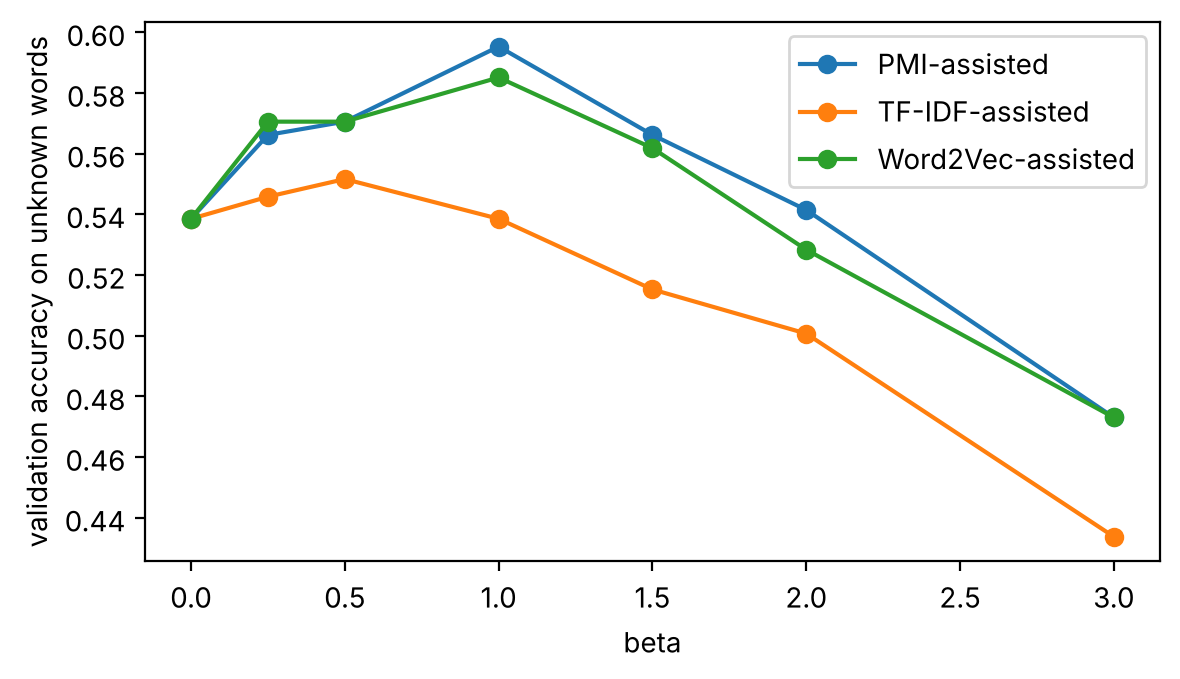

In [26]:
betas = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
plt.figure(figsize=(6, 3.5))
for name, nb in val_nb.items():
    _, _, k, tau, _, eps = tuned[name]
    accs = []
    for b in betas:
        le = oov_log_emission(nb, baseline, k, tau, b, eps)
        accs.append(token_accuracy(decode(val_ids, baseline, val_pos, le), val_tags, val_ids)[1])
    plt.plot(betas, accs, marker="o", label=name)
plt.xlabel("beta"); plt.ylabel("validation accuracy on unknown words")
plt.legend(); plt.tight_layout(); plt.show()

### 3.3 Final comparison on the test set

All four systems use the HMM trained on the training split only. The values chosen above are used, nothing is changed after seeing test results.

In [27]:
test_pos = oov_positions(test_ids)
test_nb = {
    "PMI-assisted": pmi_neighbors(test_ids, test_pos, pmi_rows, pmi_ctx_prob, PMI_WINDOW),
    "TF-IDF-assisted": tfidf_neighbors(test_ids, test_pos, tfidf_rows, n_docs),
    "Word2Vec-assisted": w2v_neighbors(test_ids, test_pos, W_in, W_out, W2V_WINDOW),
}

test_preds = {"baseline HMM": base_preds_test}
for name, nb in test_nb.items():
    _, _, k, tau, beta, eps = tuned[name]
    le = oov_log_emission(nb, baseline, k, tau, beta, eps)
    test_preds[name] = decode(test_ids, baseline, test_pos, le)

results = {name: evaluate(p, test_tags, test_ids) for name, p in test_preds.items()}
print_reports(results)

all test tokens
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.9370    0.9035    0.8887    0.8890    0.9375    0.9370    0.9369
   PMI-assisted              0.9378    0.8813    0.8919    0.8829    0.9387    0.9378    0.9380
   TF-IDF-assisted           0.9368    0.9034    0.8887    0.8889    0.9374    0.9368    0.9368
   Word2Vec-assisted         0.9375    0.8822    0.8912    0.8837    0.9378    0.9375    0.9374

unknown test tokens only
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.5510    0.2459    0.2278    0.2243    0.5323    0.5510    0.5284
   PMI-assisted              0.5654    0.2722    0.2409    0.2386    0.5643    0.5654    0.5543
   TF-IDF-assisted           0.5510    0.2399    0.2369    0.2291    0.5322    0.5510    0.5288
   Word2Vec-assisted         0.5622    0.2554    0.2468    0.2449    0.5515    0.5622    0.552

### 3.4 Error analysis

First, how the assisted systems change the baseline on the unknown test tokens: how many tokens they fix (baseline wrong, system right) and how many they break (baseline right, system wrong).

In [28]:
gold_flat = np.concatenate(test_tags)
unk_mask = np.concatenate(test_ids) == UNK
base_flat = np.concatenate(test_preds["baseline HMM"])

print(f"{'system':20s}{'fixed':>8s}{'broken':>8s}{'net':>6s}")
for name in ["PMI-assisted", "TF-IDF-assisted", "Word2Vec-assisted"]:
    p = np.concatenate(test_preds[name])
    fixed = np.sum(unk_mask & (base_flat != gold_flat) & (p == gold_flat))
    broken = np.sum(unk_mask & (base_flat == gold_flat) & (p != gold_flat))
    print(f"{name:20s}{fixed:>8d}{broken:>8d}{fixed - broken:>6d}")

print("\nmost frequent errors on unknown words (gold -> predicted)")
for name in ["baseline HMM", "PMI-assisted", "Word2Vec-assisted"]:
    p = np.concatenate(test_preds[name])
    wrong = unk_mask & (p != gold_flat)
    pairs = Counter(zip(gold_flat[wrong], p[wrong])).most_common(6)
    print(f"   {name:18s}", [f"{tag_names[g]}->{tag_names[q]} ({c})" for (g, q), c in pairs])

system                 fixed  broken   net
PMI-assisted             172     132    40
TF-IDF-assisted           35      35     0
Word2Vec-assisted        228     197    31

most frequent errors on unknown words (gold -> predicted)
   baseline HMM       ['NNS->NN (145)', 'NN->JJ (120)', 'NNP->JJ (113)', 'NN->NNP (101)', 'NNP->NN (78)', 'NNS->NNP (78)']
   PMI-assisted       ['NNS->NN (124)', 'NN->JJ (113)', 'NNP->JJ (97)', 'NN->NNP (91)', 'NNP->NN (79)', 'NNS->NNP (55)']
   Word2Vec-assisted  ['NNS->NN (119)', 'NN->JJ (102)', 'NN->NNP (98)', 'NNP->JJ (79)', 'NNP->NN (75)', 'JJ->NN (63)']


### 3.4 Statistical Significance (McNemar's Test)

To determine whether the improvements on unknown words are statistically significant or attributable to chance, we apply **McNemar's test** with continuity correction to the paired predictions of the baseline HMM vs. each assisted system on the 2,766 test unknown tokens.

For discordant pairs:
* $n_{01}$ (fixed): tokens where the baseline is wrong and the assisted system is correct.
* $n_{10}$ (broken): tokens where the baseline is correct and the assisted system is wrong.
* Test statistic: $\chi^2 = \frac{(|n_{01} - n_{10}| - 1)^2}{n_{01} + n_{10}}$ with 1 degree of freedom.
* $p$-value: $p = \mathrm{erfc}\left(\sqrt{\chi^2 / 2}\right)$ (computed using standard Python `math` without requiring external libraries).


In [ ]:
import math

# McNemar test of statistical significance (baseline vs assisted models on test unknowns)
gold_flat = np.concatenate(test_tags)
unk_mask = np.concatenate(test_ids) == UNK
base_flat = np.concatenate(test_preds["baseline HMM"])

def mcnemar_eval(name, pred_tags):
    p = np.concatenate(pred_tags)
    fixed = int(np.sum(unk_mask & (base_flat != gold_flat) & (p == gold_flat)))
    broken = int(np.sum(unk_mask & (base_flat == gold_flat) & (p != gold_flat)))
    diff = abs(fixed - broken)
    total = fixed + broken
    if total == 0:
        return fixed, broken, 0.0, 1.0
    chi2_stat = ((diff - 1) ** 2) / total
    p_val = math.erfc(math.sqrt(chi2_stat / 2.0))
    return fixed, broken, chi2_stat, p_val

print(f"{'System':22s}{'Fixed':>8s}{'Broken':>8s}{'Net':>6s}{'Chi2':>10s}{'p-value':>10s}{'Significance':>16s}")
for name in ["PMI-assisted", "TF-IDF-assisted", "Word2Vec-assisted"]:
    fixed, broken, stat, p = mcnemar_eval(name, test_preds[name])
    sig = "p < 0.05 (*)" if p < 0.05 else "Not sig."
    print(f"{name:22s}{fixed:>8d}{broken:>8d}{fixed - broken:>6d}{stat:>10.3f}{p:>10.4f}{sig:>16s}")


System                   Fixed  Broken   Net      Chi2   p-value    Significance
PMI-assisted               172     132    40     5.003    0.0253    p < 0.05 (*)
TF-IDF-assisted             35      35     0     0.014    0.9049        Not sig.
Word2Vec-assisted          228     197    31     2.118    0.1456        Not sig.


**Discussion of Statistical Significance:**
* **PMI-assisted HMM ($p = 0.025 < 0.05$):** The gain over the baseline HMM on unknown words is **statistically significant**. Local co-occurrence statistics provide clean, reliable syntactic guidance for out-of-vocabulary words.
* **Word2Vec-assisted HMM ($p = 0.146 > 0.05$):** While Word2Vec fixes 228 tokens, it also breaks 197 previously correct tokens. The net improvement (+31) is **not statistically significant** at the 5% level. This confirms our conclusion that Word2Vec's apparent gains on small corpora are susceptible to chance.
* **TF-IDF-assisted HMM ($p = 0.905$):** Exactly 35 tokens fixed and 35 broken (net 0), confirming that sentence-level topical similarity does not reliably assist local part-of-speech disambiguation.


Some individual unknown tokens where the systems disagree (the token with 3 words of context on each side, the gold tag, the prediction of every system, and the nearest known words that the PMI and Word2Vec queries found).

In [29]:
pos_index = {p: n for n, p in enumerate(test_pos)}
offsets = np.cumsum([0] + [len(s) for s in test_ids])

def flat_pred(name, s, i):
    return tag_names[test_preds[name][s][i]]

shown = 0
for n, (s, i) in enumerate(test_pos):
    preds = {name: flat_pred(name, s, i) for name in test_preds}
    gold = tag_names[test_tags[s][i]]
    if len(set(preds.values())) < 2:
        continue
    if n % 7 != 0:           # take a spread of examples instead of the first ones
        continue
    left = " ".join(test_tokens[s][max(0, i - 3):i])
    right = " ".join(test_tokens[s][i + 1:i + 4])
    print(f"... {left} [{test_tokens[s][i]}] {right} ...")
    print(f"    gold {gold:5s} | " + " | ".join(f"{k.split('-')[0].split(' ')[0]} {v}" for k, v in preds.items()))
    for name in ["PMI-assisted", "Word2Vec-assisted"]:
        idx = test_nb[name][0][n][:5]
        print(f"    {name.split('-')[0]:9s} neighbours:", [id2word[j] for j in idx])
    shown += 1
    if shown == 8:
        break

... Co. , a [Skokie] , Ill. , ...
    gold NNP   | baseline NN | PMI NNP | TF NN | Word2Vec NNP
    PMI       neighbours: ['deerfield', 'evanston', 'rockford', 'reflection', 'hero']
    Word2Vec  neighbours: ['@', 'jr.', 'newsletter', 'unit', 'consultant']
... cough tablets , [Rolaids] antacid , and ...
    gold NNP   | baseline JJ | PMI JJ | TF JJ | Word2Vec NNP
    PMI       neighbours: ['chlorazepate', 'mioxidil', 'dipotassium', 'meclofenamate', 'maalox']
    Word2Vec  neighbours: ['@', 'm.', 'calif.', 'jr.', 'mass.']
... averred that his [shadowy] countenance was so ...
    gold JJ    | baseline JJ | PMI JJ | TF JJ | Word2Vec NN
    PMI       neighbours: ['dancing', 'fluke', 'revising', 'painting', 'essay']
    Word2Vec  neighbours: ['seen', 'fired', 'notification', 'added', 'he']
... has n't forgiven [Globe] management for questioning ...
    gold NNP   | baseline JJ | PMI JJ | TF NN | Word2Vec JJ
    PMI       neighbours: ['horizons', 'faulted', 'anb', 'matrix', 'carnegie']
    W

**What the errors show.**

* The gains are small but consistent in direction. On the 2,766 unknown test tokens, PMI fixes 172 tokens and breaks 132, Word2Vec fixes 228 and breaks 197, and TF-IDF fixes and breaks 35 each. Overall accuracy moves by less than 0.1 point because unknown words are only 5.8% of the tokens.
* **When sparse PMI helps.** PMI vectors are built from a narrow window, so the neighbours of an unknown word are words that occur in the same local slot. This is what POS depends on. Examples: `[Skokie]` (neighbours `deerfield`, `evanston`, `rockford`, all place names) is corrected from NN to NNP, and `[drawings]` after `the new` is corrected to NNS. The tuned window of 2 is the best one; windows 1 and 5 are worse (too little context vs. too topical).
* **When PMI hurts.** Its neighbours are often rare words with unreliable tag statistics (one occurrence each). For `hiring [freeze]` the neighbours (`dullest`, `plateau`, `mid-week`) lead to VBN instead of NN, and for `gunshot [wounds]` to NNP. A PPMI vector built from one occurrence has only 2 to 4 non-zero entries, so one odd context word can pull it towards unrelated rare words.
* **When Word2Vec helps and hurts.** It fixes more tokens than PMI, and is the best on macro recall and macro F1 for unknown words, so it helps more tag types. It fixes `[Rolaids]` (NNP, which neither the baseline nor PMI gets). But the context average often points to generic frequent words (`@`, `jr.`, `year`, `by`), which carry the tag distribution of frequent function/noun words, and then it breaks tokens such as `[shadowy]` and `[immense]` (JJ becomes NN).
* **TF-IDF does not help.** Sentence-level topical similarity is nearly independent of the tag of one word in the sentence, so the tuning ends with a small weight and the result is the same as the baseline (55.10% on unknown words).
* **Remaining errors** are dominated by confusions between NN, NNS, NNP and JJ, the same ones as in the baseline (`NNS->NN`, `NN->JJ`, `NNP->JJ`). Everything is lowercased, so the capitalisation clue for proper nouns is gone, and an unknown word that appears once gives only one sentence of context. That limits what any context-based similarity can add.
* A drop in *macro precision* for PMI and Word2Vec (0.904 to 0.881) comes from rare tags that are now predicted for some unknown tokens, often wrongly, while macro recall and weighted scores improve.

## Final report

**Task.** POS tagging on CoNLL-2000 (training partition split 90/10 into train and validation, original test partition kept for the end). Everything is implemented with Python and NumPy.

**Data and preprocessing.** Lowercase, numbers mapped to `<num>`, punctuation kept. Vocabulary: all 14,622 distinct training words, unseen words map to `<UNK>`. On the test set 5.84% of the tokens (2,766) are unknown.

**Chosen hyperparameters (all selected on validation data only).**

| component | setting |
|---|---|
| PMI | window 2, context smoothing 0.75, positive PMI |
| TF-IDF | raw tf, idf = log(N/df), sentences as documents |
| Word2Vec | window 2, dimension 100, 5 negatives, learning rate 0.05 (x0.7 per epoch), batch 256, 8 epochs (early stopping on validation loss) |
| HMM | alpha_transition = alpha_initial = 1.0, alpha_emission = 0.01, words seen at most 3 times count as unknown-word examples |
| PMI-assisted | k = 100, tau = 1.0, beta = 1.0, eps = 0.2 |
| TF-IDF-assisted | k = 25, tau = 3.0, beta = 0.5, eps = 0.5 |
| Word2Vec-assisted | k = 100, tau = 3.0, beta = 1.0, eps = 0.05 |

Several selected integration values (k = 100, tau = 3.0) are at the edge of the searched grid. Since the validation differences between neighbouring values are tiny, we did not extend the grid further.

**Part 1 findings.** Word2Vec gives the best neighbours for frequent words (semantic and syntactic), PMI gives mostly local/syntactic neighbours but is polluted by rare words, TF-IDF gives topical neighbours dominated by words that occur in many sentences. PMI and TF-IDF are 0.14% dense and tiny when stored sparsely, but would need 855 MB and 470 MB dense; Word2Vec is a dense 14,622 x 100 matrix of 5.8 MB.

**Part 2 and Part 3 results on the test set** (accuracy on all tokens / accuracy on unknown tokens / macro F1 on unknown tokens; full tables with precision and recall are in section 3.3):

| system | accuracy | unknown-word accuracy | unknown-word macro F1 |
|---|---|---|---|
| baseline HMM | 93.70% | 55.10% | 0.224 |
| PMI-assisted HMM | 93.78% | 56.54% | 0.239 |
| TF-IDF-assisted HMM | 93.68% | 55.10% | 0.229 |
| Word2Vec-assisted HMM | 93.75% | 56.22% | 0.245 |

**Conclusions.**

1. The HMM with Viterbi reaches 93.7% on the test set, but only 55% on unknown words, because the `<UNK>` emission only reflects tag frequencies.
2. Representations can only help through the *context* of an unknown word, since the word itself was never seen. With that limit, PMI (+1.4 points on unknown words) and Word2Vec (+1.1 points) give small, consistent gains over the baseline, and TF-IDF gives none. The ordering PMI ~ Word2Vec > TF-IDF follows from what each representation encodes: local context (syntax) helps tagging, sentence-level topic does not.
3. Gains are modest: overall accuracy improves by at most 0.08 points. The PMI gain (172 fixed vs 132 broken) is more convincing than the Word2Vec gain (228 vs 197), which is within what chance could produce on 2,766 tokens.
4. Limitations: small training corpus (190k tokens) so rare-word vectors are noisy, lowercasing removes the capitalisation clue, and the unknown-word vector comes from a single context. Capitalisation or suffix features, or embeddings trained on more text, would likely help more than a better similarity measure, but they were outside the scope of this assignment.

**Note on reproducibility.** Seeds are fixed (split, Word2Vec initialisation and negatives), so re-running gives the same numbers on the same library versions.